## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.svm import LinearSVC, SVC
from sklearn.linear_model import LogisticRegression
from collections import Counter
from wordcloud import WordCloud
from sklearn.pipeline import Pipeline

## Load dataset

In [2]:
train_data = pd.read_csv('train.txt', sep='\t', header=None, names=['title', 'from', 'genre', 'director', 'plot'])

test_data = pd.read_csv('test_no_labels.txt', sep='\t', header=None, names=['title', 'from', 'director', 'plot'])

genres = list(train_data['genre'].unique())

## Pre-processing

In [3]:
stop_words = set(stopwords.words('english')) 
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = re.sub(r'\(\b([A-Z][a-z]*\s?)+\)', '', text)  # Remove text in brackets that starts with a capital letter (actors names)
    text = text.lower() 
    text = re.sub(r'http\S+', '', text) 
    #text = re.sub(r"[^a-zA-Z+']", ' ', text)  # Keep only characters
    text = "".join([i for i in text if i not in string.punctuation])
    words = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(i) for i in words if i not in stop_words])
    text = re.sub("\s[\s]+", " ", text).strip()  # Remove repeated/leading/trailing spaces
    return text

train_data['Text_cleaning'] = train_data['plot'].apply(clean_text) 
test_data['Text_cleaning'] = test_data['plot'].apply(clean_text)

train_data['Text_cleaning'].head()

0    sekhar graduate iim work business manager firm...
1    kris fowles go springwood diner meet exboyfrie...
2    cynthia traumatized death baby leaving bathtub...
3    four friend gangu abdul nihal gary form word g...
4    crisis middleclass family son fall love father...
Name: Text_cleaning, dtype: object

## Statistics

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(y='genre' , data=train_data , order=train_data['genre'].value_counts().index, palette='viridis')
plt.title('Genre Distribution',fontweight='bold')
plt.xlabel('Count', fontweight='bold')
plt.ylabel('Genre', fontweight='bold')
plt.xticks(rotation=90)
plt.show()

In [ ]:
# Count the number of words in each 'plot' entry
train_data['plot_word_count'] = train_data['plot'].apply(lambda x: len(str(x).split()))

# Plot a histogram of word counts
plt.figure(figsize=(10,6))
plt.hist(train_data['plot_word_count'], bins=20, edgecolor='black', color='skyblue')
plt.title('Histogram of Word Counts in Plot Descriptions')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

print("Mean: ", train_data['plot_word_count'].mean())
print("Median: ", train_data['plot_word_count'].median())

### Frequency By Genre 

In [ ]:
for genre in genres:
    genre_data = train_data[train_data['genre'] == genre].copy()
    print(len(genre_data))
    genre_data['words'] = genre_data['Text_cleaning'].apply(lambda x: x.split())

    # Concatenate all tokens for the genre
    all_words = [word for tokens in genre_data['words'] for word in tokens]

    # Get the most common words
    word_counts = Counter(all_words)

    print("-----", genre, "-----")
    print(word_counts.most_common(10))  # You can keep this line if you still want to print the counts

    # Create a word cloud
    wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate_from_frequencies(word_counts)

    # Plot the word cloud
    plt.figure(figsize=(8, 4))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  # Turn off axis
    plt.title(f'Word Cloud for {genre}', fontweight='bold')
    #plt.show()  # Show the word cloud


In [ ]:
from collections import Counter
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Combine all words across all genres
test_data['words'] = test_data['Text_cleaning'].apply(lambda x: x.split())  # Assuming 'Text_cleaning' column has cleaned text data
all_words = [word for tokens in test_data['words'] for word in tokens]

# Count the frequencies of the words
word_counts = Counter(all_words)

# Print the top 10 most common words
print("----- Overall Most Common Words in Test Data -----")
print(word_counts.most_common(10))

# Create the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate_from_frequencies(word_counts)

# Plot the word cloud
plt.figure(figsize=(8, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Turn off axis
plt.title('Overall Word Cloud for Test Data', fontweight='bold')
plt.show()  # Show the word cloud

### Models

#### 1. Vectors

In [7]:
# Initialize the vectorizer stuff (possibel to use max_features=num_features)
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, max_features=20000)
count_vectorizer = CountVectorizer()

# Fit and transform the text data in two flavours
X_train = tfidf_vectorizer.fit_transform(train_data['Text_cleaning'])
X_test = tfidf_vectorizer.transform(test_data['Text_cleaning'])
Z_train = count_vectorizer.fit_transform(train_data['Text_cleaning'])

#### 2. Train/test split

In [5]:
X = X_train
Z = Z_train
y = train_data['genre']
train_indices, val_indices, y_train, y_val = train_test_split(range(len(train_data)), y, test_size=0.1, random_state=40)

X_train, X_val = X[train_indices], X[val_indices]
Z_train, Z_val = Z[train_indices], Z[val_indices]

#### 3. K-fold Cross Validation

In [10]:
folds = 10
model = SVC(kernel='linear')
#model = LogisticRegression(solver='lbfgs', max_iter=1000)
#model = LinearSVC()#class_weight='balanced')
# Cross validation
cv_predictions = cross_val_predict(model, X_train, train_data['genre'], cv=folds)

print("WITH CROSS VALIDATION, WITH:", folds, "folds")
print(accuracy_score(y_pred=cv_predictions, y_true=train_data['genre']))
print(classification_report(y_pred=cv_predictions, y_true=train_data['genre'], zero_division=1.))
# Find the indexes where the prediction was wrong
wrong_indexes = train_data[train_data['genre'] != cv_predictions].index

print("Wrong predictions:", len(wrong_indexes))

# Write the wrong predictions and corresponding plots to a file
with open("wrong_predictions.txt", "w") as f:
    for idx in wrong_indexes:
        f.write(f"Index: {idx}, Plot: {train_data['plot'][idx]}\n")
        f.write(f"Actual genre: {train_data['genre'][idx]}, Predicted: {cv_predictions[idx]}\n")
        
print("The wrong predictions have been written to 'wrong_predictions.txt'.")

WITH CROSS VALIDATION, WITH: 10 folds
0.6872279567218008
              precision    recall  f1-score   support

      action       0.66      0.70      0.68      1059
   animation       0.88      0.72      0.79       535
      comedy       0.60      0.61      0.61      1193
       crime       0.64      0.48      0.55       541
       drama       0.55      0.70      0.62      1676
      horror       0.85      0.86      0.85      1108
     romance       0.64      0.50      0.56       886
      sci-fi       0.75      0.40      0.52       214
     western       0.95      0.91      0.93       829

    accuracy                           0.69      8041
   macro avg       0.72      0.65      0.68      8041
weighted avg       0.70      0.69      0.69      8041

Wrong predictions: 2515
The wrong predictions have been written to 'wrong_predictions.txt'.


##### SVM

In [ ]:
print("==== SVM ====")
clf = SVC(kernel='linear')

print("Resultados com tfidf")
clf.fit(X_train, y_train)
x_pred=clf.predict(X_val)
print("Validation Accuracy:", accuracy_score(x_pred, y_val))
print(classification_report(y_pred=x_pred, y_true=y_val, zero_division=1.))

# Identify misclassified examples and print the wrong predictions vs correct genres and their plots
print("\n==== Misclassified Predictions ====")
misclassified_indices = [i for i, (true, pred) in enumerate(zip(y_val, x_pred)) if true != pred]
print(len(misclassified_indices), " were misclassified\n")

for idx in misclassified_indices:
    # Use the original index from y_val to access the correct plot
    original_index = y_val.index[idx]  # Get the index of the original y_val
    print(f"\nPlot: {train_data['plot'][original_index]}")
    print(f"Ground truth: {y_val.iloc[idx]}, Predicted genre: {x_pred[idx]}")

# Write the wrong predictions and corresponding plots to a file
with open("wrong_predictions.txt", "w") as f:
    for idx in misclassified_indices:
        original_index = y_val.index[idx]  # Get the index of the original y_val
        f.write(f"\nPlot: {train_data['plot'][original_index]}\n")
        f.write(f"Ground truth: {y_val.iloc[idx]}, Predicted genre: {x_pred[idx]}\n")

#print("Resultados com count")
#clf.fit(Z_train, y_train)
#z_pred=clf.predict(Z_val)
#print(classification_report(y_pred=z_pred, y_true=y_val, zero_division=1.))

##### Tuning of Hyperparameters

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(train_data['Text_cleaning'], train_data['genre'], test_size=0.1, random_state=40)

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),  # TfidfVectorizer step
    ('svm', SVC())                 # SVM classifier step
])

# Define the parameter grid for both TfidfVectorizer and SVM
param_dist = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],  # Test unigrams, bigrams, and trigrams
    'tfidf__max_df': [0.7, 0.85, 1.0],              # Ignore overly common words
    'tfidf__min_df': [1, 2, 5],                     # Ignore very rare words
    'tfidf__max_features': [5000, 10000, 20000],     # Limit the number of features
    'svm__kernel': ['linear', 'rbf'],        # SVM kernel types to try
    'svm__C': np.logspace(-2, 2, 5),                    # SVM regularization parameter
    'svm__gamma': ['scale', 'auto']                 # Kernel coefficient for rbf and poly kernels
}

# Set up GridSearchCV with the SVC model
grid_search = RandomizedSearchCV(estimator=pipeline, param_distributions=param_dist, n_iter=30,
                           scoring='accuracy', cv=3, n_jobs=-1, verbose=2)

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Get the best parameters and model
print(f"Best parameters found: {grid_search.best_params_}")
best_svm = grid_search.best_estimator_

# Predict and evaluate on validation set
y_pred = best_svm.predict(X_val)
print(classification_report(y_val, y_pred))

##### LinearSVC

In [ ]:
print("==== LinearSVC ====")
clf = LinearSVC() 

print("Resultados com tfidf")
clf.fit(X_train, y_train)
x_pred=clf.predict(X_val)
print("Validation Accuracy:", accuracy_score(x_pred, y_val))
print(classification_report(y_pred=x_pred, y_true=y_val, zero_division=1.))

print("Resultados com count")
clf.fit(Z_train, y_train)
z_pred=clf.predict(Z_val)
print(classification_report(y_pred=z_pred, y_true=y_val, zero_division=1.))

##### LogisticRegression

In [ ]:
print("==== LogisticRegression ====")
clf = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)

print("Resultados com tfidf")
clf.fit(X_train, y_train)
x_pred=clf.predict(X_val)
print(classification_report(y_pred=x_pred, y_true=y_val, zero_division=1.))

print("Resultados com count")
clf.fit(Z_train, y_train)
z_pred=clf.predict(Z_val)
print(classification_report(y_pred=z_pred, y_true=y_val, zero_division=1.))

##### RandomForests

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train CountVectorizer
count_vectorizer = CountVectorizer(ngram_range=(1, 2), max_features=20000)
X_count = count_vectorizer.fit_transform(train_data['Text_cleaning'])

# Splitting the data into training and validation sets
y = train_data['genre']
X_train, X_val, y_train, y_val = train_test_split(X_count, y, test_size=0.1, random_state=40)

# Train Random Forest on the count vectors
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

# Validate on the validation set
y_pred = rf_clf.predict(X_val)
print("Resultados com Random Forest + Bag-of-Words")
print(classification_report(y_val, y_pred, zero_division=1))


In [ ]:
from gensim.models import Word2Vec
import numpy as np

# Train Word2Vec model on the tokenized movie plots
tokenized_plots = [word_tokenize(plot.lower()) for plot in train_data['Text_cleaning']]
word2vec_model = Word2Vec(sentences=tokenized_plots, vector_size=200, window=5, min_count=2, workers=4)

# Function to convert a plot into a Word2Vec embedding
def plot_to_embedding(plot, model):
    words = word_tokenize(plot.lower())
    embeddings = [model.wv[word] for word in words if word in model.wv]
    if embeddings:
        return np.mean(embeddings, axis=0)
    else:
        return np.zeros(model.vector_size)

# Apply Word2Vec transformation to the cleaned plots
X_w2v = np.array([plot_to_embedding(plot, word2vec_model) for plot in train_data['Text_cleaning']])

# Splitting the data
y = train_data['genre']
X_train, X_val, y_train, y_val = train_test_split(X_w2v, y, test_size=0.1, random_state=40)

# Train Random Forest on the Word2Vec embeddings
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)

# Validate on the validation set
y_pred = rf_clf.predict(X_val)
print("Resultados com Random Forest + Word2Vec")
print(classification_report(y_val, y_pred, zero_division=1))


##### MultinomialNB

In [ ]:
print("==== MultinomialNB ====")
clf = MultinomialNB()

print("Resultados com tfidf")
clf.fit(X_train, y_train)
x_pred=clf.predict(X_val)
print(classification_report(y_pred=x_pred, y_true=y_val, zero_division=1.))

print("Resultados com count")
clf.fit(Z_train, y_train)
z_pred=clf.predict(Z_val)
print(classification_report(y_pred=z_pred, y_true=y_val, zero_division=1.))

##### GaussianNB (Requires .toarray(), kernel dies)

In [ ]:
print("==== GaussianNB ====")
clf = GaussianNB()

print("Resultados com tfidf")
clf.fit(X_train, y_train)
x_pred=clf.predict(X_val)
print(classification_report(y_pred=x_pred, y_true=y_val, zero_division=1.))

print("Resultados com count")
clf.fit(Z_train, y_train)
z_pred=clf.predict(Z_val)
print(classification_report(y_pred=z_pred, y_true=y_val, zero_division=1.))

#### 7. Save model predictions

In [ ]:
# Use the trained model to make predictions on the test data
X_test_predictions = classifier.predict(X_test)

# Save the predictions to 'results.txt' with each predicted genre in a new line
with open('results.txt', 'w') as file:
    for genre in X_test_predictions:
        file.write(genre + '\n')

print("Predictions saved to results.txt")

### Confusion matrix

Confusion Matrix:
[[ 742   11   46   38  116   31   63    4    8]
 [  22  385   45    0   42   19    5   13    4]
 [  58   14  730   27  274   16   63    1   10]
 [  76    0   54  262  128   11    3    0    7]
 [  93    9  185   55 1177   34  114    1    8]
 [  15    2   30   13   85  948    4    9    2]
 [  75    2   99    4  259    1  444    0    2]
 [  29   16    8    0   13   60    0   86    2]
 [  11    0   21   10   31    1    3    0  752]]


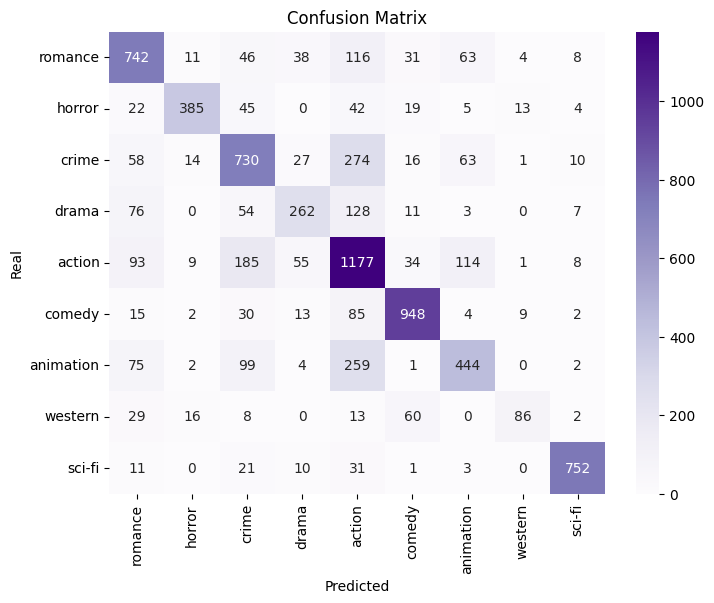

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

cm = confusion_matrix(train_data['genre'], cv_predictions)

# Print the results
print("Confusion Matrix:")
print(cm)
plt.figure(figsize=(8, 6), dpi=100)
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=genres, yticklabels=genres)

plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('Confusion Matrix')
plt.show()

# Compute the confusion matrix
#cm = confusion_matrix(y_val, x_pred, labels=genres)

# Display the confusion matrix
#print("Confusion Matrix:")
#disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=genres)
#disp.plot()

# Show the plot
#plt.show()

In [ ]:
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from scipy.sparse import hstack, csr_matrix

# Load training data
train_data = pd.read_csv('train.txt', sep='\t', header=None, names=['title', 'from', 'genre', 'director', 'plot'])

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Clean the text
def clean_text(text):
    text = re.sub(r'\(\b([A-Z][a-z]*\s?)+\)', '', text)  # Remove actor names
    text = text.lower()
    text = re.sub(r'http\S+', '', text)
    text = "".join([i for i in text if i not in string.punctuation])
    words = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(i) for i in words if i not in stop_words])
    text = re.sub("\s[\s]+", " ", text).strip()  # Remove repeated/leading/trailing spaces
    return text

train_data['Text_cleaning'] = train_data['plot'].apply(clean_text)

# Initialize the TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(smooth_idf=True, ngram_range=(1, 2), use_idf=True, sublinear_tf=True, max_features=20000)
X_train_tfidf = tfidf_vectorizer.fit_transform(train_data['Text_cleaning'])

# Genre-Specific Frequent Words
genre_words = {
    'romance': ['love', 'family', 'life', 'friend', 'meet'],
    'horror': ['kill', 'death', 'house', 'body', 'find'],
    'action': ['police', 'kill', 'escape', 'fight', 'weapon'],
    'comedy': ['funny', 'laugh', 'friend', 'life', 'family'],
    'crime': ['police', 'murder', 'gang', 'detective', 'kill'],
    'drama': ['life', 'family', 'father', 'mother', 'find'],
    'sci-fi': ['alien', 'space', 'future', 'planet', 'ship'],
    'western': ['town', 'ranch', 'cowboy', 'gun', 'horse'],
    'animation': ['animal', 'child', 'adventure', 'magic', 'cartoon']
}

def extract_top_n_words_by_genre(train_data, n=10):
    genre_word_counts = {}
    for genre in train_data['genre'].unique():
        genre_data = train_data[train_data['genre'] == genre]['Text_cleaning']
        all_words = ' '.join(genre_data).split()
        word_freq = Counter(all_words)
        genre_word_counts[genre] = [word for word, _ in word_freq.most_common(n)]
    return genre_word_counts

# Example usage:
#genre_words = extract_top_n_words_by_genre(train_data, n=10)

# Create genre-word-based features with frequency counts
def create_genre_word_features(plot, genre_words):
    features = {}
    for genre, words in genre_words.items():
        for word in words:
            # Initialize the feature if it doesn't exist
            features[f'{genre}_word_{word}'] = features.get(f'{genre}_word_{word}', 0)
            # Increment if the word is present in the plot
            features[f'{genre}_word_{word}'] += 1 if word in plot.lower() else 0
    return features

# Combine TF-IDF with genre-word features
def combine_features(X, X_train_tfidf, genre_words):
    extra_features = []
    for plot in X:
        plot_features = {}
        plot_features.update(create_genre_word_features(plot, genre_words))
        extra_features.append(plot_features)
    
    vec = DictVectorizer()
    extra_features_vec = vec.fit_transform(extra_features)
    
    # Combine TF-IDF with genre-word-based features
    return hstack([X_train_tfidf, extra_features_vec])

# Splitting the data into training and validation sets
y = train_data['genre']
train_indices, val_indices, y_train, y_val = train_test_split(range(len(train_data)), y, test_size=0.1, random_state=40)

# Apply combination of features only to the training set
X_train_combined = combine_features(train_data['Text_cleaning'].iloc[train_indices], X_train_tfidf[train_indices], genre_words)

# Apply combination of features to the validation set
X_val_combined = combine_features(train_data['Text_cleaning'].iloc[val_indices], X_train_tfidf[val_indices], genre_words)

# Convert to csr_matrix to ensure it is subscriptable
X_train_combined = csr_matrix(X_train_combined)
X_val_combined = csr_matrix(X_val_combined)

# Train the SVM model (Linear Kernel)
clf = SVC(kernel='linear')
clf.fit(X_train_combined, y_train)

# Validate on the validation set
y_pred_val = clf.predict(X_val_combined)
print("Resultados com TF-IDF + Genre-Specific Word Features")
print(classification_report(y_pred=y_pred_val, y_true=y_val, zero_division=1.))